In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/netflix_clean.csv", parse_dates=["date_added"])
by_release = df.groupby("release_year").size()
print(by_release.index.min(), by_release.index.max(), len(by_release))
print(by_release.tail(15))

1925 2021 74
release_year
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     351
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
dtype: int64


In [2]:
all_years = range(by_release.index.min(), by_release.index.max() + 1)
missing_years = sorted(set(all_years) - set(by_release.index))
print(len(missing_years), missing_years[:10])
print(by_release.loc[:1999].sum(), by_release.loc[2000:].sum())

23 [1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934, 1935]
525 8261


In [3]:
recent = df[df["release_year"] >= 2000]
trend = recent.groupby(["release_year", "type"]).size().unstack(fill_value=0)
trend["Total"] = trend.sum(axis=1)
trend["yoy_change_%"] = (trend["Total"].pct_change() * 100).round(1)
print(trend.tail(12))
print(trend["Total"].sum(), trend["Total"].idxmax())

type          Movie  TV Show  Total  yoy_change_%
release_year                                     
2010            153       39    192          26.3
2011            145       40    185          -3.6
2012            173       63    236          27.6
2013            225       61    286          21.2
2014            263       88    351          22.7
2015            396      159    555          58.1
2016            658      243    901          62.3
2017            765      265   1030          14.3
2018            766      378   1144          11.1
2019            632      397   1029         -10.1
2020            517      436    953          -7.4
2021            277      315    592         -37.9
8261 2018


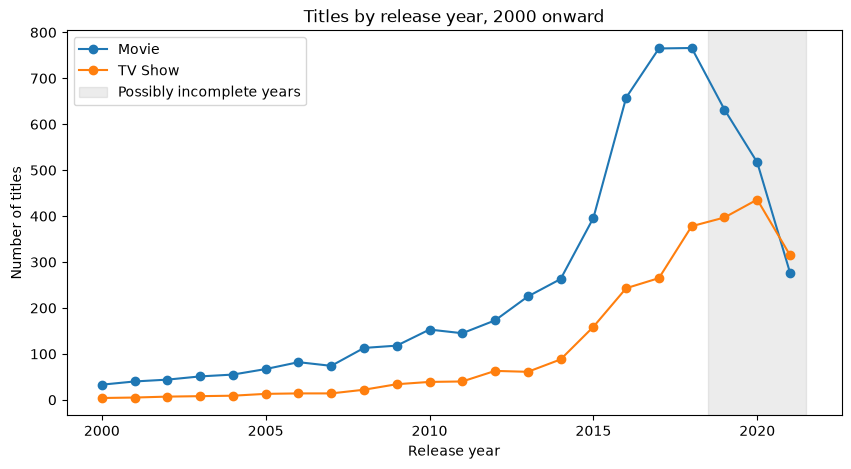

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(trend.index, trend["Movie"], marker="o", label="Movie")
plt.plot(trend.index, trend["TV Show"], marker="o", label="TV Show")
plt.axvspan(2018.5, 2021.5, alpha=0.15, color="gray", label="Possibly incomplete years")
plt.title("Titles by release year, 2000 onward")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.legend()
plt.show()

In [5]:
import numpy as np

series = trend.loc[2000:2018, "Total"]
train = series.loc[:2015]
test = series.loc[2016:]
print(len(train), len(test))

16 3


In [6]:
x_train = train.index.values - 2000
x_test = test.index.values - 2000

line = np.polyfit(x_train, train.values, 1)
pred_line = np.polyval(line, x_test)

expo = np.polyfit(x_train, np.log(train.values), 1)
pred_exp = np.exp(np.polyval(expo, x_test))

pred_naive = np.full(len(test), train.iloc[-1])

results = pd.DataFrame({"actual": test.values,
                        "naive": pred_naive.round(0),
                        "linear": pred_line.round(0),
                        "exponential": pred_exp.round(0)}, index=test.index)
print(results)

for name in ["naive", "linear", "exponential"]:
    print(name, "average error:", np.abs(results["actual"] - results[name]).mean().round(1), "titles")

              actual  naive  linear  exponential
release_year                                    
2016             901    555   383.0        493.0
2017            1030    555   408.0        581.0
2018            1144    555   434.0        685.0
naive average error: 470.0 titles
linear average error: 616.7 titles
exponential average error: 438.7 titles


### Decision: how to present the forecast
On held-out years 2016 to 2018, all three models underpredicted. Average error:
naive 470 titles, linear 617, exponential 439 (about 43 to 60% of the actual
value). The exponential model was best but still far off, probably because
titles jumped sharply in 2015 and 2016, which the 2000 to 2015 training data
does not contain. The test has only 3 years, so the ranking is uncertain.
Forecasts are therefore shown as scenarios, not predictions.

In [8]:
x_all = series.index.values - 2000
y_all = series.values
future_years = np.arange(2019, 2024)
x_future = future_years - 2000

line_all = np.polyfit(x_all, y_all, 1)
expo_all = np.polyfit(x_all, np.log(y_all), 1)

forecast = pd.DataFrame({
    "linear": np.polyval(line_all, x_future).round(0),
    "exponential": np.exp(np.polyval(expo_all, x_future)).round(0),
}, index=future_years)
forecast["observed"] = trend["Total"].reindex(future_years)
print(forecast)

      linear  exponential  observed
2019   820.0       1118.0    1029.0
2020   872.0       1351.0     953.0
2021   925.0       1631.0     592.0
2022   977.0       1970.0       NaN
2023  1029.0       2380.0       NaN


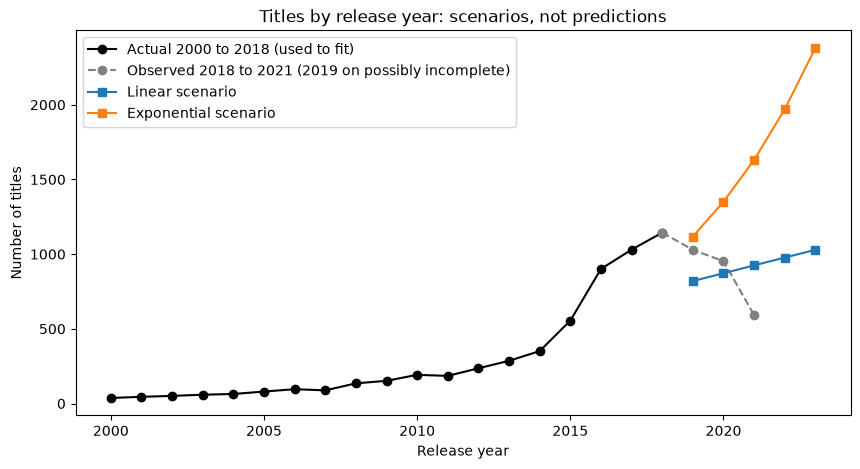

In [9]:
observed = trend.loc[2018:2021, "Total"]

plt.figure(figsize=(10, 5))
plt.plot(series.index, series.values, marker="o", color="black", label="Actual 2000 to 2018 (used to fit)")
plt.plot(observed.index, observed.values, marker="o", linestyle="--", color="gray", label="Observed 2018 to 2021 (2019 on possibly incomplete)")
plt.plot(forecast.index, forecast["linear"], marker="s", label="Linear scenario")
plt.plot(forecast.index, forecast["exponential"], marker="s", label="Exponential scenario")
plt.title("Titles by release year: scenarios, not predictions")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.legend()
plt.show()

## Interpretation

**Trend.** Titles by release year grew slowly until about 2014 (351 titles),
then jumped to 901 in 2016 and peaked at 1,144 in 2018. TV shows grew faster
than movies: their share of titles rose from 20% in 2010 to 33% in 2018.

**Models.** On held-out years 2016 to 2018, a naive baseline, a linear trend
and an exponential trend all underpredicted (average error 470, 617 and 439
titles). Refitted on 2000 to 2018, the linear scenario adds about 52 titles a
year and the exponential scenario about 21% a year. Neither tracks the observed
2019 to 2021 values consistently.

**Caveats.** Observed counts fall from 2019, but the data ends on 25 September
2021 and newer titles may not be fully captured, so the fall may not be real.
The test used only 3 years. The file is a catalogue of titles, not a count of
worldwide production, so these scenarios do not forecast real-world output.

**Conclusion.** Simple trend models cannot reliably forecast this series. The
results should be read as scenarios that show how sensitive a forecast is to
the years chosen, not as predictions.